# Análisis de la recuperación: resultados base, texto vs. tabla y variantes

Genera, a partir de los archivos de evaluación ya existentes, las cifras de recuperación que cita el documento del trabajo de grado.

| Sección de este notebook | Qué produce | Dónde se usa en el documento |
|---|---|---|
| 1 | Precisión y recall de las 9 configuraciones base y gráfico | Tabla 8 y Figura 2 |
| 2 | Resultados de las variantes H1 a H4 | Tabla 10 |
| 3 | Puntaje por tipo de evidencia y fallos completos (recall = 0) | Tabla 9, sección 9.2 y H2/H4 |
| 4 | Métricas sin LLM: porcentaje de ceros y correlación | Sección 8.8 |
| 5 | Longitud de los fragmentos de tabla recuperados | Sección 9.2 |
| 6 | Caso concreto del Factor 6 / Tabla 4 | Sección 9.2 |

Ejecutar desde la carpeta del proyecto (la que contiene `validacion/`). Salidas en `validacion/reporte_retrieval/`.

**Aviso sobre etiquetas heredadas.** En `evaluacion_ragas_resumen.csv` la columna `tipo_busqueda` de algunas filas quedó con valores que no corresponden a la configuración (por ejemplo, `bge-m3_cs800_hibrido` aparece como "rerank"). Este notebook no usa esa columna: identifica cada configuración por su nombre de archivo y de configuración.

In [ ]:
%pip install -q pandas numpy scipy openpyxl matplotlib

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

DIR_VALIDACION = Path("./validacion")
DIR_CK = DIR_VALIDACION / "checkpoints_evaluacion"
RUTA_DATASET = DIR_VALIDACION / "dataset_validacion_final.json"
RUTA_RESUMEN = DIR_VALIDACION / "evaluacion_ragas_resumen.csv"
RUTA_DETALLE = DIR_VALIDACION / "evaluacion_ragas_detalle.csv"
RUTA_RETRIEVAL = DIR_VALIDACION / "resultados_retrieval_2.json"
DIR_SALIDA = DIR_VALIDACION / "reporte_retrieval"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

PREC, REC = "llm_context_precision_with_reference", "context_recall"
MODELOS = {"openai/text-embedding-3-large": "OpenAI text-embedding-3-large",
           "google/embeddinggemma-300m": "embeddinggemma-300m",
           "BAAI/bge-m3": "bge-m3"}

resumen = pd.read_csv(RUTA_RESUMEN).set_index("configuracion")
dataset = json.load(open(RUTA_DATASET, encoding="utf-8"))["pares"]
tipo_evidencia = {p["pregunta"]: p["tipo_evidencia"] for p in dataset}

## 1. Las 9 configuraciones base (Tabla 8 y Figura 2)

In [2]:
filas = []
for modelo, nombre in MODELOS.items():
    fila = {"Modelo": nombre}
    for cs in (300, 500, 800):
        r = resumen.loc[f"{modelo}_cs{cs}"]
        fila[f"{cs} tokens (precisión)"] = r[PREC]
        fila[f"{cs} tokens (recall)"] = r[REC]
    filas.append(fila)
tabla8 = pd.DataFrame(filas)
display(tabla8.round(4))

# Formato como en el documento: "precisión / recall"
tabla8_doc = pd.DataFrame({"Modelo": tabla8["Modelo"]})
for cs in (300, 500, 800):
    tabla8_doc[f"{cs} tokens"] = [f"{p:.4f} / {r:.4f}" for p, r in zip(tabla8[f"{cs} tokens (precisión)"], tabla8[f"{cs} tokens (recall)"])]
display(tabla8_doc)

,Modelo,300 tokens (precisión),300 tokens (recall),500 tokens (precisión),500 tokens (recall),800 tokens (precisión),800 tokens (recall)
0,OpenAI text-embedding-3-large,0.7099,0.7444,0.7006,0.8100,0.7415,0.8309
1,embeddinggemma-300m,0.6928,0.7149,0.6974,0.7463,0.6654,0.7469
2,bge-m3,0.6142,0.6362,0.6037,0.6990,0.6326,0.7008


,Modelo,300 tokens,500 tokens,800 tokens
0,OpenAI text-embedding-3-large,0.7099 / 0.7444,0.7006 / 0.8100,0.7415 / 0.8309
1,embeddinggemma-300m,0.6928 / 0.7149,0.6974 / 0.7463,0.6654 / 0.7469
2,bge-m3,0.6142 / 0.6362,0.6037 / 0.6990,0.6326 / 0.7008


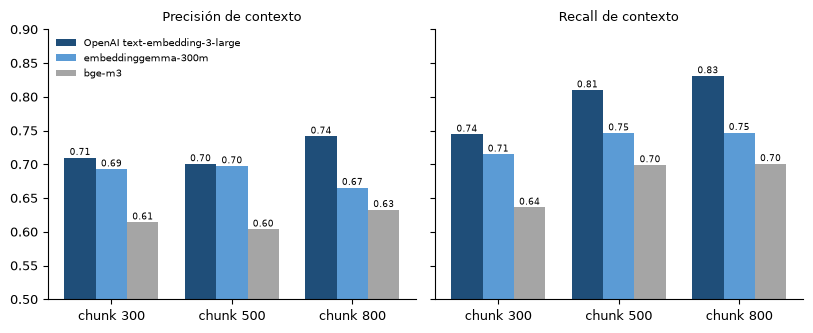

In [3]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
colores = ["#1f4e79", "#5b9bd5", "#a5a5a5"]
fig, ejes = plt.subplots(1, 2, figsize=(8.2, 3.4), sharey=True)
for eje, (col, titulo) in zip(ejes, [("precisión", "Precisión de contexto"), ("recall", "Recall de contexto")]):
    ancho = 0.26
    for i, nombre in enumerate(tabla8["Modelo"]):
        vals = [tabla8.loc[i, f"{cs} tokens ({col})"] for cs in (300, 500, 800)]
        xs = np.arange(3) + (i - 1) * ancho
        eje.bar(xs, vals, ancho, label=nombre, color=colores[i])
        for x, v in zip(xs, vals):
            eje.text(x, v + 0.004, f"{v:.2f}", ha="center", fontsize=6.5)
    eje.set_xticks(range(3)); eje.set_xticklabels(["chunk 300", "chunk 500", "chunk 800"])
    eje.set_title(titulo, fontsize=9); eje.set_ylim(0.5, 0.9)
ejes[0].legend(fontsize=7, loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "figura_configuraciones_base.png", dpi=200)
plt.show()

## 2. Variantes exploradas (Tabla 10)

Cada hipótesis compara una configuración "antes" con una "después". La variación porcentual se calcula sobre el valor "antes".

In [4]:
VARIANTES = [  # (hipótesis, antes, después)
    ("H1. Híbrido en BGE-m3 (tamaño 800, k = 5)", "BAAI/bge-m3_cs800", "BAAI/bge-m3_cs800_hibrido"),
    ("H2. BGE-m3 híbrido con k = 10",             "BAAI/bge-m3_cs800_hibrido", "BAAI/bge-m3_cs800_hibrido_k10"),
    ("H3. Gemma (tamaño 800) con k = 3",          "google/embeddinggemma-300m_cs800", "google/embeddinggemma-300m_cs800_k3"),
    ("H4. Pipeline mejorado en BGE-m3",           "BAAI/bge-m3_cs800_hibrido", "BAAI/bge-m3_con_reranking_cs800_hibrido"),
    ("H4. Pipeline mejorado en OpenAI",           "openai/text-embedding-3-large_cs800", "openai/text-embedding-3-large_cs800_hibrido"),
]
filas = []
for h, a, d in VARIANTES:
    ra, rd = resumen.loc[a], resumen.loc[d]
    filas.append({"Hipótesis": h, "Antes (precisión)": ra[PREC], "Antes (recall)": ra[REC],
                  "Después (precisión)": rd[PREC], "Después (recall)": rd[REC],
                  "Δ precisión %": 100 * (rd[PREC] / ra[PREC] - 1), "Δ recall %": 100 * (rd[REC] / ra[REC] - 1)})
tabla10 = pd.DataFrame(filas)
display(tabla10.round(4))

,Hipótesis,Antes (precisión),Antes (recall),Después (precisión),Después (recall),Δ precisión %,Δ recall %
0,"H1. Híbrido en BGE-m3 (tamaño 800, k = 5)",0.6326,0.7008,0.7013,0.7360,10.8494,5.0259
1,H2. BGE-m3 híbrido con k = 10,0.7013,0.7360,0.6349,0.8090,-9.4593,9.9227
2,H3. Gemma (tamaño 800) con k = 3,0.6654,0.7469,0.6520,0.6743,-2.0125,-9.7248
3,H4. Pipeline mejorado en BGE-m3,0.7013,0.7360,0.6883,0.7360,-1.8507,0.0077
4,H4. Pipeline mejorado en OpenAI,0.7415,0.8309,0.7719,0.7954,4.0902,-4.2692


## 3. Texto vs. tabla y fallos completos (Tabla 9, sección 9.2, H2 y H4)

Se cruza el detalle por pregunta de cada configuración con el tipo de evidencia del dataset. El **puntaje** es el promedio de precisión y recall de contexto de cada pregunta. Un **fallo completo** es una pregunta con `context_recall = 0`.

In [5]:
def cargar(archivo):
    d = pd.read_csv(DIR_CK / archivo, usecols=["user_input", PREC, REC]).set_index("user_input")
    d["puntaje"] = (d[PREC] + d[REC]) / 2
    d["tipo_evidencia"] = d.index.map(tipo_evidencia)
    assert d["tipo_evidencia"].notna().all(), "hay preguntas que no están en el dataset"
    return d

ARCHIVOS = {
    "OpenAI (cs800)": "openai/text-embedding-3-large_cs800.csv",
    "embeddinggemma (cs800)": "google/embeddinggemma-300m_cs800.csv",
    "bge-m3 denso (cs800)": "BAAI/bge-m3_cs800.csv",
    "bge-m3 híbrido (cs800, k=5)": "BAAI/bge-m3_cs800_hibrido.csv",
    "bge-m3 híbrido (cs800, k=10)": "BAAI/bge-m3_cs800_hibrido_k10.csv",
}
D = {k: cargar(f) for k, f in ARCHIVOS.items()}

# Tabla 9
filas = []
for k in ["OpenAI (cs800)", "embeddinggemma (cs800)", "bge-m3 denso (cs800)"]:
    g = D[k].groupby("tipo_evidencia")["puntaje"].mean()
    filas.append({"Modelo": k, "Texto": g["texto"], "Tabla": g["tabla"], "Brecha (texto − tabla)": g["texto"] - g["tabla"]})
tabla9 = pd.DataFrame(filas)
display(tabla9.round(3))

,Modelo,Texto,Tabla,Brecha (texto − tabla)
0,OpenAI (cs800),0.824,0.735,0.090
1,embeddinggemma (cs800),0.781,0.618,0.164
2,bge-m3 denso (cs800),0.760,0.544,0.216


In [6]:
# Fallos completos (recall = 0)
n_tabla = int((D["bge-m3 denso (cs800)"]["tipo_evidencia"] == "tabla").sum())
filas = []
for k, d in D.items():
    cero = d[REC] == 0
    filas.append({"Configuración": k, "Fallos completos (total)": int(cero.sum()),
                  "de ellos, preguntas de tabla": int((cero & (d["tipo_evidencia"] == "tabla")).sum()),
                  "% de las preguntas de tabla": 100 * (cero & (d["tipo_evidencia"] == "tabla")).sum() / n_tabla})
fallos = pd.DataFrame(filas)
display(fallos.round(1))

# Preguntas que fallan en dos configuraciones a la vez (hipótesis H4)
a, b = D["bge-m3 híbrido (cs800, k=5)"], D["OpenAI (cs800)"]
ambos = (a[REC] == 0) & (b[REC] == 0)
print(f"Preguntas con recall = 0 en bge-m3 híbrido (k=5) y OpenAI denso a la vez: {int(ambos.sum())}")
print("  de ellas, de tabla:", int((ambos & (a['tipo_evidencia'] == 'tabla')).sum()), "| de texto:", int((ambos & (a['tipo_evidencia'] == 'texto')).sum()))
fallos_ambos = pd.DataFrame({
    "Concepto": ["Recall = 0 en BGE-m3 híbrido (k=5) y OpenAI denso a la vez", "  de tabla", "  de texto"],
    "Preguntas": [int(ambos.sum()), int((ambos & (a['tipo_evidencia'] == 'tabla')).sum()), int((ambos & (a['tipo_evidencia'] == 'texto')).sum())]})

,Configuración,Fallos completos (total),"de ellos, preguntas de tabla",% de las preguntas de tabla
0,OpenAI (cs800),44,31,24.4
1,embeddinggemma (cs800),70,50,39.4
2,bge-m3 denso (cs800),82,57,44.9
3,"bge-m3 híbrido (cs800, k=5)",71,60,47.2
4,"bge-m3 híbrido (cs800, k=10)",50,45,35.4


Preguntas con recall = 0 en bge-m3 híbrido (k=5) y OpenAI denso a la vez: 26
  de ellas, de tabla: 24 | de texto: 2


## 4. Métricas sin LLM (sección 8.8)

Compara el porcentaje de ceros y la correlación de las versiones sin LLM de precisión y recall con las versiones con LLM, sobre todas las filas de `evaluacion_ragas_detalle.csv`.

In [7]:
cols = [PREC, REC, "non_llm_context_precision_with_reference", "non_llm_context_recall"]
det = pd.read_csv(RUTA_DETALLE, usecols=["configuracion"] + cols)
print("filas:", len(det), "| configuraciones:", det["configuracion"].nunique())
filas = []
for sin, con in [("non_llm_context_precision_with_reference", PREC), ("non_llm_context_recall", REC)]:
    x = det[[sin, con]].dropna()
    filas.append({"Métrica sin LLM": sin, "% de filas en cero": 100 * (x[sin] == 0).mean(),
                  "Correlación de Pearson con la versión LLM": x[sin].corr(x[con]),
                  "Correlación de Spearman con la versión LLM": x[sin].corr(x[con], method="spearman")})
sin_llm = pd.DataFrame(filas)
display(sin_llm.round(3))

filas: 4144 | configuraciones: 14


,Métrica sin LLM,% de filas en cero,Correlación de Pearson con la versión LLM,Correlación de Spearman con la versión LLM
0,non_llm_context_precision_with_reference,95.391,0.106,0.087
1,non_llm_context_recall,95.391,0.115,0.105


## 5. Longitud de los fragmentos de tabla recuperados (sección 9.2)

Para cada configuración base se toman los contextos recuperados (5 por pregunta) de tipo *tabla* y se mide su longitud en caracteres. Se reporta tanto sobre todas las recuperaciones como sobre los fragmentos distintos.

In [8]:
with open(RUTA_RETRIEVAL, encoding="utf-8") as f:
    base = json.load(f)

filas = []
for c in base["configuraciones"]:
    todas, unicas = [], {}
    for q in c["resultados"]:
        for ctx, meta in zip(q["contextos_recuperados"], q["metadatos_recuperados"]):
            if meta.get("tipo") == "tabla":
                todas.append(len(ctx)); unicas[ctx] = len(ctx)
    s, u = pd.Series(todas), pd.Series(list(unicas.values()))
    filas.append({"Modelo": MODELOS.get(c["modelo_embedding"], c["modelo_embedding"]), "Tamaño de chunk": c["chunk_size"],
                  "Tablas recuperadas": len(s), "> 3000 caracteres": int((s > 3000).sum()), "% > 3000": 100 * (s > 3000).mean(),
                  "Tablas distintas": len(u), "distintas > 3000": int((u > 3000).sum()), "Máximo (caracteres)": int(s.max())})
long_tablas = pd.DataFrame(filas)
display(long_tablas.round(1))

,Modelo,Tamaño de chunk,Tablas recuperadas,> 3000 caracteres,% > 3000,Tablas distintas,distintas > 3000,Máximo (caracteres)
0,OpenAI text-embedding-3-large,300,293,2,0.7,121,2,4393
1,OpenAI text-embedding-3-large,500,402,3,0.7,141,2,4393
2,OpenAI text-embedding-3-large,800,525,11,2.1,153,2,4393
3,bge-m3,300,197,11,5.6,91,3,6795
4,bge-m3,500,254,14,5.5,103,3,6795
5,bge-m3,800,345,25,7.2,116,4,6795
6,embeddinggemma-300m,300,295,5,1.7,119,3,6795
7,embeddinggemma-300m,500,381,3,0.8,130,3,6795
8,embeddinggemma-300m,800,475,7,1.5,138,3,6795


## 6. Caso concreto: Factor 6 y Tabla 4 (sección 9.2)

Muestra la evidencia esperada y lo que recuperó cada modelo (tamaño 800) para la pregunta sobre la calificación del Factor 6 según la Tabla 4.

In [9]:
pregunta = next(p for p in dataset if "Factor 6" in p["pregunta"] and "Tabla 4" in p["pregunta"])
print("Pregunta:", pregunta["pregunta"])
print("Respuesta esperada:", pregunta["respuesta_esperada"])
print("Evidencia esperada:", pregunta["evidencia_gold"][0][:300])
for c in base["configuraciones"]:
    if c["chunk_size"] != 800:
        continue
    q = next(r for r in c["resultados"] if r["id"] == pregunta["id"])
    print("\n==", MODELOS.get(c["modelo_embedding"]), "==")
    for i, (ctx, meta) in enumerate(zip(q["contextos_recuperados"], q["metadatos_recuperados"]), 1):
        print(f"  {i}. [{meta.get('tipo')}, p. {meta.get('pagina') or meta.get('pagina_inicio')}] {ctx[:160].strip()!r}")

Pregunta: ¿Cuál fue la calificación del Factor 6 'Permanencia y graduación' según la Tabla 4?
Respuesta esperada: El Factor 6 obtuvo una calificación de 4.6 y un grado de cumplimiento 'Plenamente'.
Evidencia esperada: Factor 6 100% 4.6 Plenamente

== OpenAI text-embedding-3-large ==
  1. [tabla, p. 184] '|**Proceso de**|**Autoevaluación A**|**ctual**||\n|---|---|---|---|\n||||**rao e**|\n|**Características**|**Ponderación**|**Calificación**|<br>**Cumplimiento**|\n|2'
  2. [tabla, p. 119] '|**Proceso de**<br>|**Autoevaluación Act**<br>|**ual**<br>|**Grado de**|\n|---|---|---|---|\n|**Características**|**Ponderación**|**Calificación**|<br>**Cumplimie'
  3. [tabla, p. 26] '|**Grado de cumplimiento**|**Intervalo de **<br>**Desde**|**Calificación**<br>**Hasta**|**Valor Porc**<br>**Desde**|**entaje (%)**<br>**Hasta**|\n|---|---|---|--'
  4. [texto, p. 203] '[tabla 1 de la pagina 203]\n**Fuente:** <u>Dirección del programa académico de Ingeniería sistemas, 2024 (ver Anexo 138)</u> \n\nEn la *

## 7. Exportar

In [10]:
with pd.ExcelWriter(DIR_SALIDA / "reporte_retrieval.xlsx") as xw:
    tabla8.to_excel(xw, sheet_name="Tabla8_base", index=False)
    tabla10.to_excel(xw, sheet_name="Tabla10_variantes", index=False)
    tabla9.to_excel(xw, sheet_name="Tabla9_texto_vs_tabla", index=False)
    fallos.to_excel(xw, sheet_name="Fallos_completos", index=False)
    fallos_ambos.to_excel(xw, sheet_name="Fallos_en_ambos", index=False)
    sin_llm.to_excel(xw, sheet_name="Metricas_sin_LLM", index=False)
    long_tablas.to_excel(xw, sheet_name="Longitud_tablas", index=False)
for nombre, t in [("tabla8_base", tabla8), ("tabla10_variantes", tabla10), ("tabla9_texto_vs_tabla", tabla9),
                  ("fallos_completos", fallos), ("fallos_en_ambos", fallos_ambos), ("metricas_sin_llm", sin_llm), ("longitud_tablas", long_tablas)]:
    t.to_csv(DIR_SALIDA / f"{nombre}.csv", index=False, encoding="utf-8-sig")
print("Guardado en", DIR_SALIDA.resolve())

Guardado en C:\Users\gomex\OneDrive\Escritorio\TG - Pruebas 2\validacion\reporte_retrieval
